# Lesson 7. Entanglement and the Bell state

**Goal:** build the Bell state step by step with matrices and understand how entanglement differs from superposition and from ordinary classical correlation.

## 1. Definition

A state $v \in \mathbb{C}^2 \otimes \mathbb{C}^2$ is a **product state** if $v = a \otimes b$ for some $a, b \in \mathbb{C}^2$. Otherwise it is **entangled**.

**Criterion for two qubits:** arrange the coordinates $v = (v_{00}, v_{01}, v_{10}, v_{11})$ into the matrix

$$M = \begin{pmatrix} v_{00} & v_{01}\\ v_{10} & v_{11}\end{pmatrix}.$$

The state is a product state if and only if $\operatorname{rank} M = 1$, i.e. $\det M = v_{00}v_{11} - v_{01}v_{10} = 0$. For $a \otimes b$ we get $M = ab^{T}$, a rank-1 matrix. (In general the Schmidt decomposition is the SVD of $M$, and its rank is the Schmidt rank.) The simple determinant test works only for two qubits.

Entanglement is **not a new axiom**: it follows from the tensor product and the Born rule. But it is not an exception either: product states form a "thin" subset, and a random state of many qubits is almost surely entangled.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
GREEN, DARK, LIGHT, GREY, ORANGE = "#44B749", "#1A8A1F", "#96E199", "#8A8A8A", "#E08A00"

e0 = np.array([1, 0], dtype=complex)   # label |0⟩
e1 = np.array([0, 1], dtype=complex)   # label |1⟩

def norm(v):
    return np.sqrt(np.sum(np.abs(v) ** 2))

def show(v, n=None):
    """Print a state vector with bit labels (label = position written in binary)."""
    v = np.asarray(v)
    n = n or int(np.log2(len(v)))
    for k, a in enumerate(v):
        if abs(a) > 1e-12:
            print(f"  position {k} ({format(k, f'0{n}b')}): amplitude {np.round(a, 3)}, P = {abs(a)**2:.3f}")

from functools import reduce
kron = lambda *ms: reduce(np.kron, ms)
I2 = np.eye(2)
H = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
CNOT = np.array([[1, 0, 0, 0],
                 [0, 1, 0, 0],
                 [0, 0, 0, 1],
                 [0, 0, 1, 0]])

def det_test(v):
    return v[0] * v[3] - v[1] * v[2]

s = 1 / np.sqrt(2)
examples = {
    "(1,0,0,0)      |00⟩":        [1, 0, 0, 0],
    "(1,1,0,0)/√2   |0⟩⊗|+⟩":     [s, s, 0, 0],
    "(1,1,1,1)/2    |+⟩⊗|+⟩":     [.5, .5, .5, .5],
    "(1,-1,1,-1)/2  |+⟩⊗|−⟩":     [.5, -.5, .5, -.5],
    "(1,i,0,0)/√2   |0⟩⊗|+i⟩":    [s, 1j * s, 0, 0],
    "(1,0,0,1)/√2   Bell Φ+":     [s, 0, 0, s],
    "(0,1,1,0)/√2   Bell Ψ+":     [0, s, s, 0],
    "(3,0,0,4)/5":                [.6, 0, 0, .8],
    "(1,1,1,-1)/2":               [.5, .5, .5, -.5],
}
for name, v in examples.items():
    d = det_test(np.array(v, dtype=complex))
    print(f"{name:>26}:  det = {np.round(np.real_if_close(d), 3):>6}   ->  {'entangled' if abs(d) > 1e-12 else 'product'}")

       (1,0,0,0)      |00⟩:  det =    0.0   ->  product
    (1,1,0,0)/√2   |0⟩⊗|+⟩:  det =    0.0   ->  product
    (1,1,1,1)/2    |+⟩⊗|+⟩:  det =    0.0   ->  product
    (1,-1,1,-1)/2  |+⟩⊗|−⟩:  det =    0.0   ->  product
   (1,i,0,0)/√2   |0⟩⊗|+i⟩:  det =    0.0   ->  product
    (1,0,0,1)/√2   Bell Φ+:  det =    0.5   ->  entangled
    (0,1,1,0)/√2   Bell Ψ+:  det =   -0.5   ->  entangled
               (3,0,0,4)/5:  det =   0.48   ->  entangled
              (1,1,1,-1)/2:  det =   -0.5   ->  entangled

Note the last two pairs:

- $(1, 1, 1, 1)/2$: all coordinates non-zero, and the state is a **product** ($u_+ \otimes u_+$);
- $(1, 1, 1, -1)/2$: differs by **one sign**, and it is **entangled**.

Entanglement is decided by the relations between coordinates, not by how many are non-zero.

| | superposition? | entangled? |
|---|---|---|
| $e_1 = \lvert 01\rangle$ | no | no |
| $u_+ \otimes e_0$ | yes | no |
| Bell state | yes | yes |

In the computational (or any product) basis, entanglement requires superposition (such basis states are always product states), but superposition does not require entanglement.

## 2. The Bell state step by step

Circuit: $H$ on qubit 0, then CNOT (qubit 0 is the control, qubit 1 the target).

**Step 0.** $v_0 = e_0 \otimes e_0 = (1, 0, 0, 0)$, label $|00\rangle$.

**Step 1.** "$H$ on qubit 0" in $\mathbb{C}^4$ is $H \otimes I$ (each entry of $H$ multiplies a whole block $I$):

$$H \otimes I = \frac{1}{\sqrt2}\begin{pmatrix}1&0&1&0\\0&1&0&1\\1&0&-1&0\\0&1&0&-1\end{pmatrix}, \qquad v_1 = (H \otimes I)v_0 = \tfrac{1}{\sqrt2}(1, 0, 1, 0).$$

This is **still a product state**: $v_1 = u_+ \otimes e_0$. There is superposition, but no entanglement.

**Step 2.** CNOT is a permutation matrix: it keeps positions 0 and 1 and swaps positions 2 and 3 (if the first bit is 1, flip the second):

$$v_2 = \mathrm{CNOT}\, v_1 = \tfrac{1}{\sqrt2}(1, 0, 0, 1) = \tfrac{1}{\sqrt2}(e_0 + e_3).$$

This is the Bell state $\Phi^+$ (labels $(|00\rangle + |11\rangle)/\sqrt2$). The matrix $M = \tfrac{1}{\sqrt2}I$ has rank 2, so the state is entangled.

**The whole circuit:** $U = \mathrm{CNOT}\,(H \otimes I)$ (right to left). The first column of $U$ is exactly $v_2$.

CNOT is **not** a tensor product $A \otimes B$ of two single-qubit gates: it acts on qubit 1 depending on the state of qubit 0. That is why it can turn a product state into an entangled one, which no gate of the form $A \otimes B$ can do.

step 0: [1. 0. 0. 0.]   det = 0.000
step 1: [0.707 0.    0.707 0.   ]   det = 0.000
step 2: [0.707 0.    0.    0.707]   det = 0.500

matrix of the whole circuit U = CNOT·(H⊗I):
 [[ 0.707  0.     0.707  0.   ]
 [ 0.     0.707  0.     0.707]
 [ 0.     0.707  0.    -0.707]
 [ 0.707  0.    -0.707  0.   ]]

Born rule for v2:
  position 0 (00): amplitude (0.707+0j), P = 0.500
  position 3 (11): amplitude (0.707+0j), P = 0.500

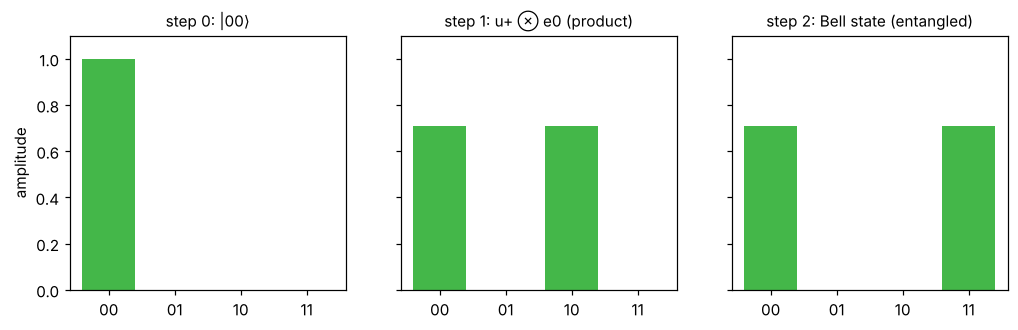

In [2]:
v0 = kron(e0, e0)
v1 = kron(H, I2) @ v0
v2 = CNOT @ v1
U = CNOT @ kron(H, I2)

for k, v in enumerate((v0, v1, v2)):
    print(f"step {k}: {np.round(v.real, 3)}   det = {det_test(v).real:.3f}")
print("\nmatrix of the whole circuit U = CNOT·(H⊗I):\n", np.round(U, 3))
print("\nBorn rule for v2:"); show(v2)

fig, axs = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
for ax, v, t in zip(axs, (v0, v1, v2), ("step 0: |00⟩", "step 1: u+ ⊗ e0 (product)", "step 2: Bell state (entangled)")):
    ax.bar(["00", "01", "10", "11"], v.real, color=[GREEN if a else "#EEE" for a in v.real])
    ax.set_title(t, fontsize=10); ax.set_ylim(0, 1.1)
axs[0].set_ylabel("amplitude")

## 3. What entanglement means physically

**The parts have no states of their own.** The whole is completely determined, yet not a single bit of information sits in the qubits separately. Measuring **only** qubit 0, in any basis, always gives 50/50. For a single qubit in a pure state there is always a basis with a certain outcome; for a qubit taken out of a Bell state there is no such basis (on the Bloch sphere it is the centre of the ball).

**Measuring one qubit fixes the other.** Outcome 0 on qubit 0 (probability 1/2) leaves the positions with first bit 0, after normalisation $e_0 = |00\rangle$, so qubit 1 is certainly 0. Outcome 1 gives $e_3 = |11\rangle$.

**How is this different from two envelopes containing the same random slip of paper?** Envelopes also give perfect correlation in one basis. The difference shows up in another basis: $(H \otimes H)v_2 = v_2$, so in the $x$ basis the Bell state looks the same and the outcomes still always agree (++ or −−). Classical envelopes in the $x$ basis give two independent coin flips. For $\Phi^+$ the outcomes are perfectly correlated in both $z$ and $x$ (and perfectly anti-correlated in $y$: $(Y \otimes Y)v_2 = -v_2$). That already rules out the simple envelope model, but not every hidden-variable model: imagine two slips per envelope, one for $z$ and one for $x$ (this was the EPR argument). Ruling all of them out takes the Bell test below.

With measurements at different angles, the Bell (CHSH) inequality shows that no model with hidden "slips in envelopes" reproduces the statistics of the Bell state, and experiments confirm quantum mechanics (loophole-free tests in 2015: Hensen et al., Giustina et al., Shalm et al.; Nobel Prize 2022). A 00/11 histogram in a single basis (like slide 6 with ibm_fez) does not prove this by itself.

**What entanglement does not do:** it does not transmit information. Someone holding only qubit 1 always sees 50/50, whatever was done to qubit 0. The correlation becomes visible only after comparing results over an ordinary channel.

In [3]:
print("(H⊗H)·v2 =", np.round(kron(H, H) @ v2, 3), " -> the same vector")
Y = np.array([[0, -1j], [1j, 0]])
print("(Y⊗Y)·v2 =", np.round(kron(Y, Y) @ v2, 3), " -> minus the same vector: in the y basis the outcomes always disagree")

rng = np.random.default_rng(3)
N = 10_000

def shots(v, x_basis):
    w = kron(H, H) @ v if x_basis else v            # measuring in the x basis = apply H⊗H first
    k = rng.choice(4, size=N, p=np.abs(w) ** 2)
    a, b = k // 2, k % 2
    return np.mean(a == b)

# classical envelopes: with probability 1/2 both "0" (e0⊗e0), with 1/2 both "1" (e1⊗e1)
def envelopes(x_basis):
    agree = 0
    for _ in range(N // 10):
        v = kron(e0, e0) if rng.random() < 0.5 else kron(e1, e1)
        w = kron(H, H) @ v if x_basis else v
        k = rng.choice(4, p=np.abs(w) ** 2)
        agree += (k // 2 == k % 2)
    return agree / (N // 10)

for x_basis, name in ((False, "z basis"), (True, "x basis")):
    print(f"{name}: Bell state -> outcomes agree {shots(v2, x_basis):.0%},  envelopes -> {envelopes(x_basis):.0%}")

(H⊗H)·v2 = [0.707+0.j 0.   +0.j 0.   +0.j 0.707+0.j]  -> the same vector
(Y⊗Y)·v2 = [-0.707+0.j  0.   +0.j  0.   +0.j -0.707+0.j]  -> minus the same vector: in the y basis the outcomes always disagree
z basis: Bell state -> outcomes agree 100%,  envelopes -> 100%
x basis: Bell state -> outcomes agree 100%,  envelopes -> 53%

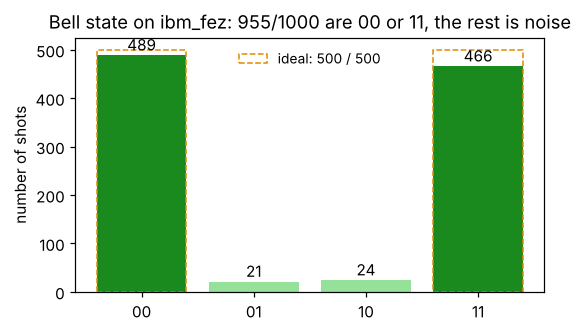

In [4]:
# The same state on real hardware: ibm_fez, 1000 shots (slide 6 of the talk)
ibm = {"00": 489, "01": 21, "10": 24, "11": 466}
fig, ax = plt.subplots(figsize=(5.5, 3))
ax.bar(ibm.keys(), ibm.values(), color=[DARK, LIGHT, LIGHT, DARK])
ax.bar(["00", "11"], [500, 500], fill=False, edgecolor=ORANGE, ls="--", label="ideal: 500 / 500")
for k, n in ibm.items():
    ax.text(k, n + 10, n, ha="center")
ax.set_ylabel("number of shots"); ax.legend(frameon=False, fontsize=9)
ax.set_title("Bell state on ibm_fez: 955/1000 are 00 or 11, the rest is noise")

## 4. Entanglement as a resource

- Circuits without entanglement can be simulated efficiently on classical computers: each qubit is a separate vector in $\mathbb{C}^2$, memory grows linearly. Entanglement is necessary for the exponential cost of simulation (16 PiB for 50 qubits), but not sufficient: Clifford circuits create highly entangled states and are still efficiently simulable (Gottesman–Knill theorem).
- Teleportation, entanglement-based quantum key distribution (E91; BB84 does not need it) and error correction all rely on entanglement.
- Entanglement can be quantified (Schmidt rank, entanglement entropy): it is a whole theory of its own.

## Summary

> Entanglement is not a new rule, just a name for vectors that are not tensor products; for two qubits the test is $\det M \ne 0$. The state of the whole is completely determined, but the parts have no states of their own, and all the information sits in correlations which cannot be reproduced by any local classical model (Bell, CHSH). Only multi-qubit gates such as CNOT create it.

## Exercises

1. Compute $H \otimes I$ by hand and check step 1.
2. What does the circuit (H, then CNOT) produce if you start from $e_1 = |01\rangle$? Is the result entangled? (The four inputs $e_0, \dots, e_3$ give the four Bell states: a basis of $\mathbb{C}^4$ made entirely of entangled states.)
3. What happens if you swap the order: first CNOT, then $H$ on qubit 0?
4. Check by hand that $(H \otimes H)\tfrac{1}{\sqrt2}(1, 0, 0, 1) = \tfrac{1}{\sqrt2}(1, 0, 0, 1)$.